In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/itsm/all_tickets.csv")

print("OpsMind AI - Business Analytics")
print("Total Incidents:", len(df))
print("Total Columns:", len(df.columns))

OpsMind AI - Business Analytics
Total Incidents: 48549
Total Columns: 9


In [2]:
total_incidents = df.shape[0]

print("Total Incident Tickets:", total_incidents)

Total Incident Tickets: 48549


In [3]:
category_incidents = df["category"].value_counts()

category_incidents

category
4     34061
5      9634
6      2628
7       921
11      612
8       239
9       191
3       137
1        72
12       45
0         4
2         3
10        2
Name: count, dtype: int64

In [4]:
category_incidents.head(5)

category
4     34061
5      9634
6      2628
7       921
11      612
Name: count, dtype: int64

In [5]:
(category_incidents / len(df) * 100).round(2)

category
4     70.16
5     19.84
6      5.41
7      1.90
11     1.26
8      0.49
9      0.39
3      0.28
1      0.15
12     0.09
0      0.01
2      0.01
10     0.00
Name: count, dtype: float64

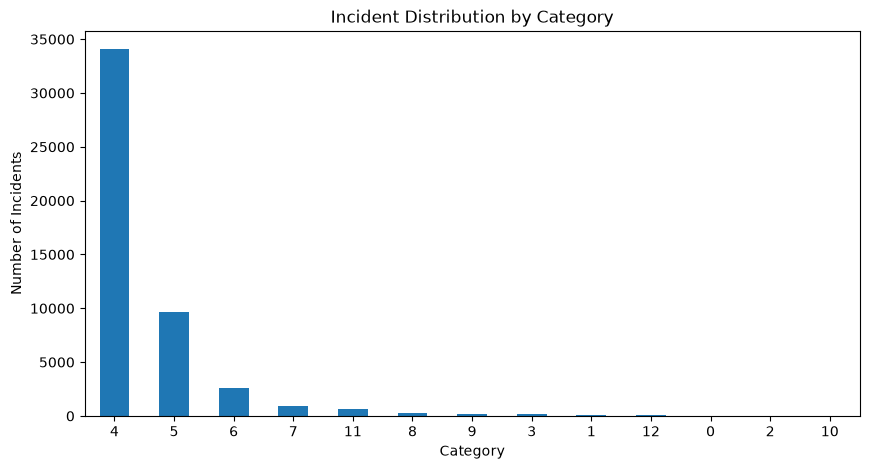

In [6]:
category_incidents.plot(
    kind="bar",
    figsize=(10, 5),
    title="Incident Distribution by Category"
)

plt.xlabel("Category")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=0)
plt.show()

In [7]:
ticket_type_counts = df["ticket_type"].value_counts()
ticket_type_counts

ticket_type
1    34621
0    13928
Name: count, dtype: int64

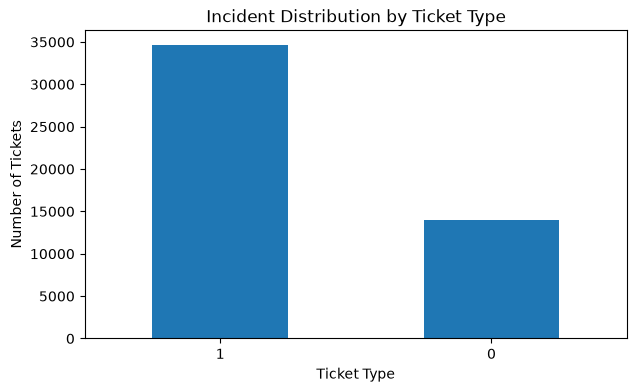

In [8]:
ticket_type_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Incident Distribution by Ticket Type"
)

plt.xlabel("Ticket Type")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.show()

In [10]:
urgency_counts = df["urgency"].value_counts().sort_index()
urgency_counts

urgency
0     1652
1     6748
2     5528
3    34621
Name: count, dtype: int64

In [11]:
(urgency_counts / len(df) * 100).round(2)

urgency
0     3.40
1    13.90
2    11.39
3    71.31
Name: count, dtype: float64

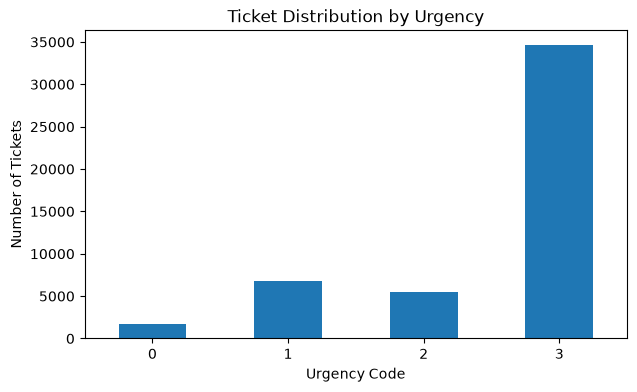

In [12]:
urgency_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Ticket Distribution by Urgency"
)

plt.xlabel("Urgency Code")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.show()

In [13]:
impact_counts = df["impact"].value_counts().sort_index()
impact_counts

impact
0      471
1       45
2      228
3    13184
4    34621
Name: count, dtype: int64

In [14]:
(impact_counts / len(df) * 100).round(2)

impact
0     0.97
1     0.09
2     0.47
3    27.16
4    71.31
Name: count, dtype: float64

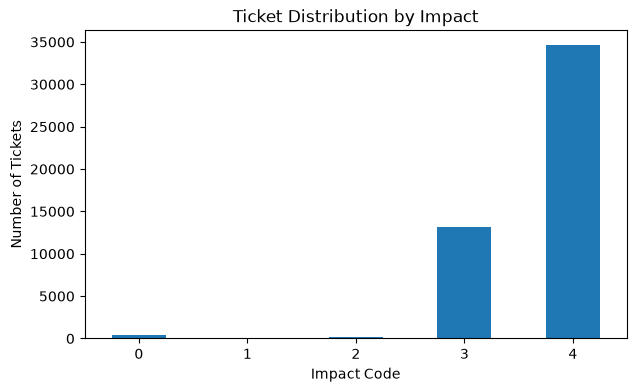

In [15]:
impact_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Ticket Distribution by Impact"
)

plt.xlabel("Impact Code")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.show()

In [16]:
service_counts = df["business_service"].value_counts()

service_counts.head(10)

business_service
32    8174
36    3685
68    3589
67    2858
4     2527
40    2199
63    1997
46    1984
56    1910
73    1882
Name: count, dtype: int64

In [17]:
(service_counts.head(10) / len(df) * 100).round(2)

business_service
32    16.84
36     7.59
68     7.39
67     5.89
4      5.21
40     4.53
63     4.11
46     4.09
56     3.93
73     3.88
Name: count, dtype: float64

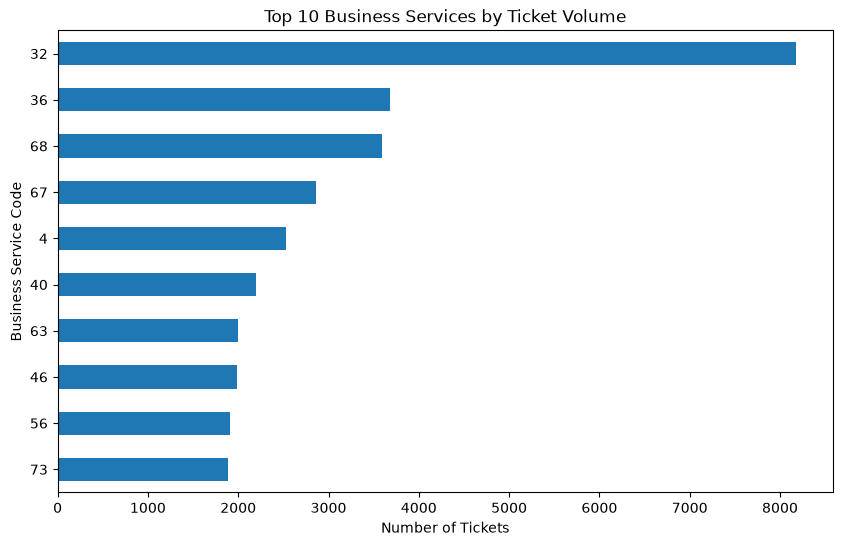

In [18]:
service_counts.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Business Services by Ticket Volume"
)

plt.xlabel("Number of Tickets")
plt.ylabel("Business Service Code")
plt.show()

In [19]:
subcat1_counts = df["sub_category1"].value_counts()

subcat1_counts.head(10)

sub_category1
2     9857
3     8324
1     7857
13    6487
21    5710
51    2402
22    1475
15    1226
9     1114
12     624
Name: count, dtype: int64

In [20]:
(subcat1_counts.head(10) / len(df) * 100).round(2)

sub_category1
2     20.30
3     17.15
1     16.18
13    13.36
21    11.76
51     4.95
22     3.04
15     2.53
9      2.29
12     1.29
Name: count, dtype: float64

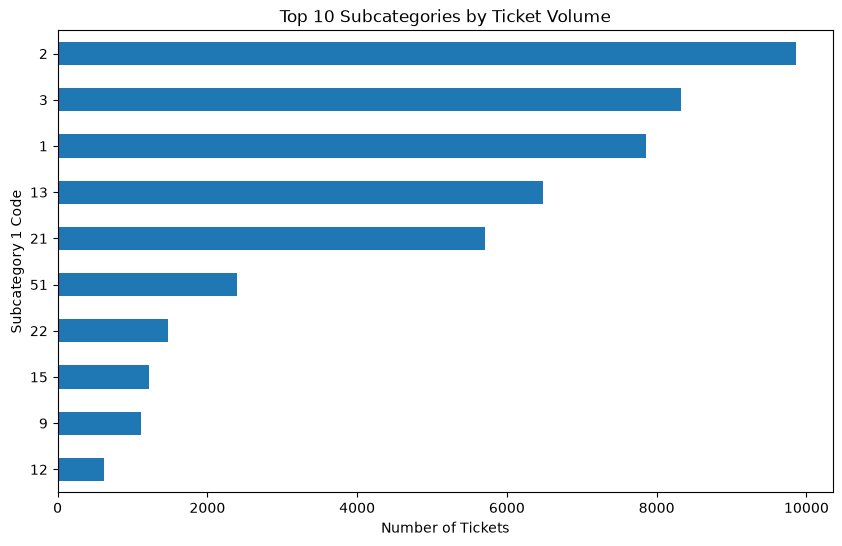

In [21]:
subcat1_counts.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Subcategories by Ticket Volume"
)

plt.xlabel("Number of Tickets")
plt.ylabel("Subcategory 1 Code")
plt.show()

In [22]:
pd.crosstab(df["ticket_type"], df["urgency"])

urgency,0,1,2,3
ticket_type,,,,
0,1652,6748,5528,0
1,0,0,0,34621


In [23]:
pd.crosstab(
    df["ticket_type"],
    df["urgency"],
    normalize="index"
).mul(100).round(2)

urgency,0,1,2,3
ticket_type,,,,
0,11.86,48.45,39.69,0.0
1,0.00,0.00,0.00,100.0


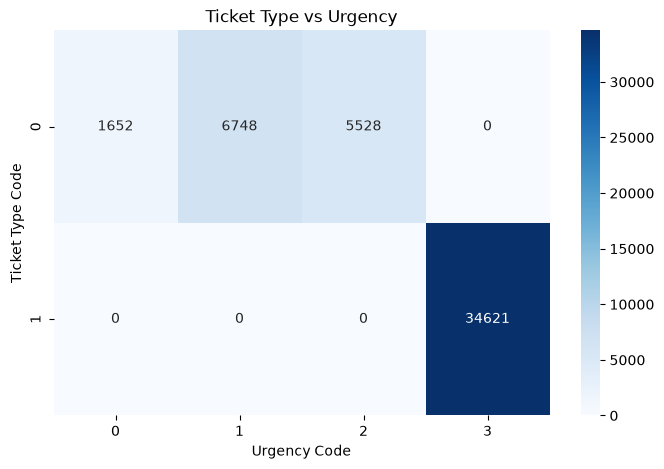

In [24]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    pd.crosstab(df["ticket_type"], df["urgency"]),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Ticket Type vs Urgency")
plt.xlabel("Urgency Code")
plt.ylabel("Ticket Type Code")
plt.show()

In [25]:
pd.crosstab(df["ticket_type"], df["impact"])

impact,0,1,2,3,4
ticket_type,,,,,
0,471,45,228,13184,0
1,0,0,0,0,34621


In [26]:
pd.crosstab(
    df["ticket_type"],
    df["impact"],
    normalize="index"
).mul(100).round(2)

impact,0,1,2,3,4
ticket_type,,,,,
0,3.38,0.32,1.64,94.66,0.0
1,0.00,0.00,0.00,0.00,100.0


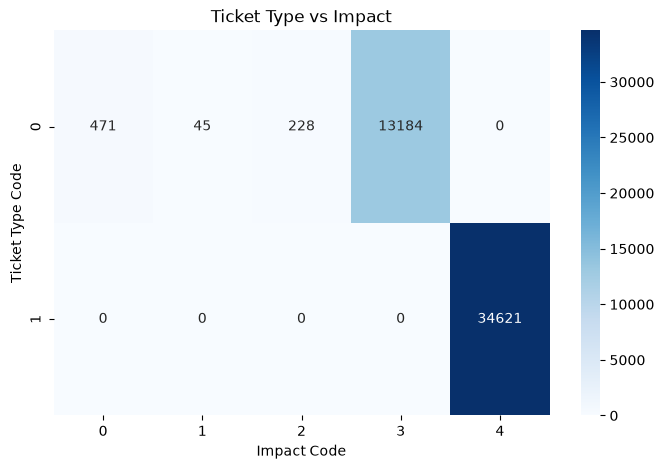

In [27]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    pd.crosstab(df["ticket_type"], df["impact"]),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Ticket Type vs Impact")
plt.xlabel("Impact Code")
plt.ylabel("Ticket Type Code")
plt.show()

### Business Insight: Ticket Type vs Impact

1. Ticket Type 0 contains 13,928 tickets.
2. 94.66% of Type 0 tickets have Impact Code 3.
3. Ticket Type 1 contains 34,621 tickets.
4. 100% of Type 1 tickets have Impact Code 4.
5. Ticket Type and Impact show a strong association in this dataset.

Note: Actual business meanings of encoded values must be verified
using the dataset documentation.

In [28]:
pd.crosstab(
    df["category"],
    df["business_service"]
)

business_service,0,1,2,3,4,5,6,7,8,9,...,93,94,95,96,97,98,99,100,101,102
category,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,2,8,0,0,0,0,0,...,0,1,0,2,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,0,10,71,80,2452,63,4,6,4,6,...,125,38,122,218,1,3,106,15,11,12
5,0,0,3,0,52,105,0,0,0,0,...,0,0,10,23,3,1,0,409,0,0
6,0,0,1,111,9,0,1,2,1,1,...,0,0,844,26,4,1,16,0,0,0
7,0,0,0,0,2,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
8,1,0,0,2,0,1,0,0,0,0,...,0,0,2,0,1,0,2,0,0,0


In [29]:
category_service = df.groupby(
    ["category", "business_service"]
).size().sort_values(ascending=False)

category_service.head(10)

category  business_service
5         32                  7536
4         36                  3622
          68                  3570
          67                  2827
          4                   2452
          40                  2197
          46                  1964
          56                  1873
          70                  1688
          51                  1411
dtype: int64

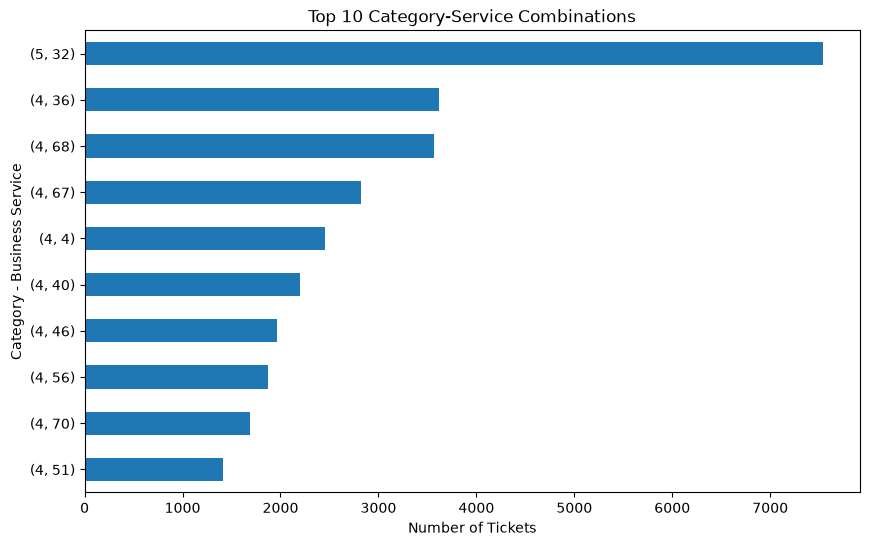

In [30]:
category_service.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Category-Service Combinations"
)

plt.xlabel("Number of Tickets")
plt.ylabel("Category - Business Service")
plt.show()

In [31]:
category_service.head(10)

category  business_service
5         32                  7536
4         36                  3622
          68                  3570
          67                  2827
          4                   2452
          40                  2197
          46                  1964
          56                  1873
          70                  1688
          51                  1411
dtype: int64

### Business Insight: Category vs Business Service

1. Category 5 and Business Service 32 form the highest-volume combination.
2. Category 4 appears across multiple high-volume business services.
3. Ticket volume is concentrated in a few category-service combinations.
4. These combinations can be prioritized for further investigation
   and potential automation.

Note: Category and business service codes require documentation
to understand their actual business meanings.

## Final Business Insights – OpsMind AI

### 1. Dataset Overview
- Total IT incident tickets: 48,549
- Total columns: 9
- Missing values found in the title column: 712
- Duplicate records: 0

### 2. Category Analysis
- Category 4 represents 70.16% of all tickets.
- Category 5 represents 19.84%.
- The top three categories account for approximately 95.41% of tickets.

### 3. Ticket Type Analysis
- Ticket Type 0: 13,928 tickets.
- Ticket Type 1: 34,621 tickets.
- Ticket Type 1 represents approximately 71.31% of the dataset.

### 4. Urgency and Impact Analysis
- Ticket Type 1 has only Urgency Code 3 and Impact Code 4.
- Ticket Type 0 has multiple urgency and impact codes.
- Ticket type, urgency and impact show strong associations in this dataset.

### 5. Business Service Analysis
- Ticket volume varies significantly across business service codes.
- A few category-service combinations account for a large number of tickets.
- These combinations can be prioritized for further investigation.

### 6. Data Quality Observations
- No duplicate records were found.
- The title column contains missing values.
- Several numerical columns represent encoded categorical values and require a codebook.

### 7. Overall Conclusion
The exploratory analysis reveals significant concentration of tickets across categories, ticket types and business service combinations.

These findings will guide the next stages of OpsMind AI, including data preprocessing, feature engineering and machine learning.

**Important:** Actual SLA compliance, MTTR and MTTA cannot be calculated from this dataset because the required timestamp and SLA fields are not available.

## KPI Availability and Limitations

| KPI | Required Data | Current Status |
|---|---|---|
| Total Incident Volume | Ticket ID / Records | Available |
| Category Distribution | Category | Available |
| Ticket Type Distribution | Ticket Type | Available |
| Urgency Distribution | Urgency | Available |
| Impact Distribution | Impact | Available |
| MTTR | Resolution Timestamp | Not Available |
| MTTA | Acknowledgement Timestamp | Not Available |
| SLA Compliance | SLA Target and Resolution Time | Not Available |
| Downtime | Downtime Duration | Not Available |

### Data Limitations

1. The dataset does not contain incident creation timestamps.
2. Resolution and acknowledgement timestamps are unavailable.
3. SLA target information is missing.
4. Several fields use numerical category codes.
5. Additional datasets will be required for time-based operational KPIs.

### Next Action

Use additional ITSM data to build time-based KPI analysis and
develop machine learning models for incident prediction.